In [1]:
# CELL 01 — Import required libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date, timedelta
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, precision_recall_curve, roc_curve
)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)


In [2]:
# CELL 02 — Create project folders
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Project folders are ready.")


Project folders are ready.


In [3]:
# CELL 03 — Generate 50,000 synthetic leads
# This is a synthetic practice dataset, not real company/customer data.
n = 500000
rng = np.random.default_rng(RANDOM_STATE)

channels = ["Website", "Email", "Facebook", "Google Ads", "Instagram", "Referral"]
products = ["Product A", "Product B", "Product C", "Product D"]

channel = rng.choice(channels, size=n, p=[0.24, 0.20, 0.14, 0.18, 0.16, 0.08])
product_interest = rng.choice(products, size=n, p=[0.32, 0.28, 0.23, 0.17])

prior_website_visits = rng.poisson(lam=5, size=n).clip(0, 25)
prior_email_engagement_count = rng.poisson(lam=3, size=n).clip(0, 18)

# Lead dates stop at least 30 days before today, so every lead has a full outcome window.
last_eligible_date = date.today() - timedelta(days=30)
first_date = last_eligible_date - timedelta(days=364)
date_range_days = (last_eligible_date - first_date).days
random_days = rng.integers(0, date_range_days + 1, size=n)
lead_created_date = pd.to_datetime([first_date + timedelta(days=int(x)) for x in random_days])

leads = pd.DataFrame({
    "lead_id": [f"LD{num:06d}" for num in range(1, n + 1)],
    "lead_created_date": lead_created_date,
    "channel": channel,
    "product_interest": product_interest,
    "prior_website_visits": prior_website_visits,
    "prior_email_engagement_count": prior_email_engagement_count
})

leads.head()


,lead_id,lead_created_date,channel,product_interest,prior_website_visits,prior_email_engagement_count
0,LD000001,2026-08-26,Instagram,Product B,2,3
1,LD000002,2026-07-11,Email,Product A,6,4
2,LD000003,2026-05-30,Instagram,Product D,5,6
3,LD000004,2026-09-20,Google Ads,Product B,8,2
4,LD000005,2026-03-13,Website,Product C,7,4


In [4]:
# CELL 04 — Create the 30-day conversion target
# The target is generated from pre-scoring activity and a small amount of random variation.
channel_effect = pd.Series(channel).map({
    "Website": 0.25, "Email": 0.55, "Facebook": -0.15,
    "Google Ads": 0.10, "Instagram": -0.05, "Referral": 0.65
}).to_numpy()

product_effect = pd.Series(product_interest).map({
    "Product A": 0.20, "Product B": 0.05,
    "Product C": -0.10, "Product D": 0.15
}).to_numpy()

conversion_score = (
    0.95 * prior_website_visits
    + 1.25 * prior_email_engagement_count
    + channel_effect
    + product_effect
    + rng.normal(0, 1.0, size=n)
)

# A median-based boundary creates both classes; small random label noise avoids a perfectly clean rule.
boundary = np.median(conversion_score)
converted_30d = (conversion_score >= boundary).astype(int)
flip_mask = rng.random(n) < 0.015
converted_30d[flip_mask] = 1 - converted_30d[flip_mask]

leads["converted_30d"] = converted_30d
print(leads["converted_30d"].value_counts())
print("Conversion rate:", round(leads["converted_30d"].mean() * 100, 2), "%")


converted_30d
1    250002
0    249998
Name: count, dtype: int64
Conversion rate: 50.0 %


In [5]:
# CELL 05 — Save the raw dataset
raw_file = "data/lead_conversion_raw1.csv"
leads.to_csv(raw_file, index=False)
print("Saved:", raw_file)


Saved: data/lead_conversion_raw1.csv


In [6]:
# CELL 06 — Load the raw dataset
df = pd.read_csv(raw_file, parse_dates=["lead_created_date"])
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (500000, 7)


,lead_id,lead_created_date,channel,product_interest,prior_website_visits,prior_email_engagement_count,converted_30d
0,LD000001,2026-08-26,Instagram,Product B,2,3,0
1,LD000002,2026-07-11,Email,Product A,6,4,1
2,LD000003,2026-05-30,Instagram,Product D,5,6,1
3,LD000004,2026-09-20,Google Ads,Product B,8,2,0
4,LD000005,2026-03-13,Website,Product C,7,4,1


In [8]:
# CELL 07 — Inspect and validate the dataset
print(df.info())
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nDuplicate lead IDs:", df["lead_id"].duplicated().sum())
print("\\nTarget counts:")
print(df["converted_30d"].value_counts())
print("\\nDate range:", df["lead_created_date"].min(), "to", df["lead_created_date"].max())

assert len(df) == 500000
assert set(df["converted_30d"].unique()).issubset({0, 1})
assert (df["lead_created_date"].max() <= pd.Timestamp(date.today() - timedelta(days=30)))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   lead_id                       500000 non-null  object        
 1   lead_created_date             500000 non-null  datetime64[ns]
 2   channel                       500000 non-null  object        
 3   product_interest              500000 non-null  object        
 4   prior_website_visits          500000 non-null  int64         
 5   prior_email_engagement_count  500000 non-null  int64         
 6   converted_30d                 500000 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 26.7+ MB
None
\nMissing values:
lead_id                         0
lead_created_date               0
channel                         0
product_interest                0
prior_website_visits            0
prior_email_engagement_c

In [9]:
# CELL 08 — Handle missing values and prepare the analysis copy
# Add a small number of missing feature values to make preprocessing meaningful.
df_model = df.copy()
missing_rng = np.random.default_rng(RANDOM_STATE + 1)

for column, fraction in [
    ("prior_website_visits", 0.01),
    ("prior_email_engagement_count", 0.01),
    ("channel", 0.005),
    ("product_interest", 0.005)
]:
    missing_rows = missing_rng.choice(df_model.index, size=int(len(df_model) * fraction), replace=False)
    df_model.loc[missing_rows, column] = np.nan

print("Missing values introduced for preprocessing practice:")
print(df_model.isnull().sum())


Missing values introduced for preprocessing practice:
lead_id                            0
lead_created_date                  0
channel                         2500
product_interest                2500
prior_website_visits            5000
prior_email_engagement_count    5000
converted_30d                      0
dtype: int64


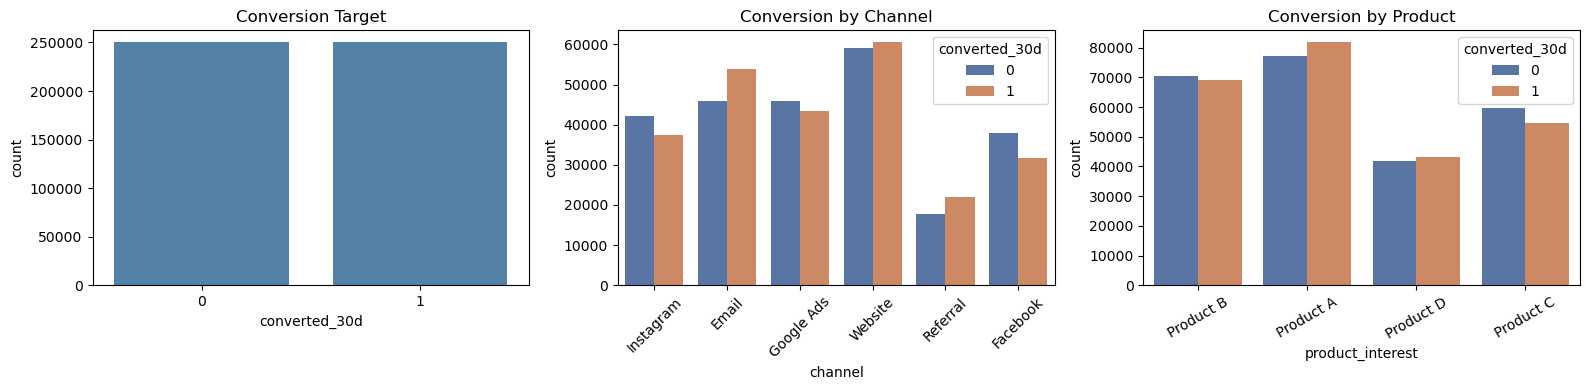

In [10]:
# CELL 09 — Visualize target and categorical features
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df_model, x="converted_30d", color="steelblue", ax=axes[0])
axes[0].set_title("Conversion Target")

sns.countplot(data=df_model, x="channel", hue="converted_30d", palette="deep", ax=axes[1])
axes[1].set_title("Conversion by Channel")
axes[1].tick_params(axis="x", rotation=45)

sns.countplot(data=df_model, x="product_interest", hue="converted_30d", palette="deep", ax=axes[2])
axes[2].set_title("Conversion by Product")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


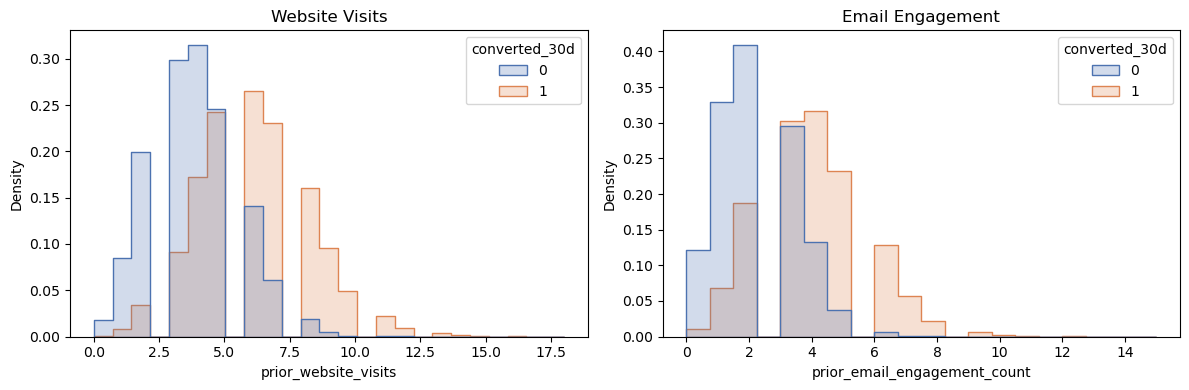

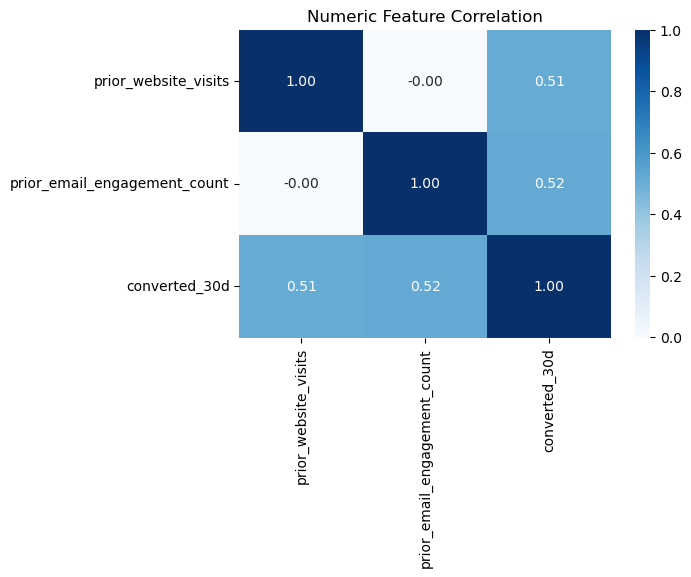

In [11]:
# CELL 10 — Visualize numeric features and correlation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_model, x="prior_website_visits", hue="converted_30d",
             bins=25, element="step", stat="density", common_norm=False, palette="deep", ax=axes[0])
axes[0].set_title("Website Visits")
sns.histplot(data=df_model, x="prior_email_engagement_count", hue="converted_30d",
             bins=20, element="step", stat="density", common_norm=False, palette="deep", ax=axes[1])
axes[1].set_title("Email Engagement")
plt.tight_layout()
plt.show()

numeric_view = df_model[[
    "prior_website_visits", "prior_email_engagement_count", "converted_30d"
]].copy()
plt.figure(figsize=(6, 4))
sns.heatmap(numeric_view.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Numeric Feature Correlation")
plt.show()


In [12]:
# CELL 11 — Select model features and target
# ID and date are retained for sorting/auditing, but are not model features.
numeric_columns = ["prior_website_visits", "prior_email_engagement_count"]
categorical_columns = ["channel", "product_interest"]
feature_columns = numeric_columns + categorical_columns
target_column = "converted_30d"

df_model = df_model.sort_values("lead_created_date").reset_index(drop=True)
X = df_model[feature_columns].copy()
y = df_model[target_column].astype(int).copy()

print("Features:", feature_columns)
print("Target:", target_column)


Features: ['prior_website_visits', 'prior_email_engagement_count', 'channel', 'product_interest']
Target: converted_30d


In [13]:
# CELL 12 — Chronological train, validation, and test split
# Older leads train the model; later leads validate and test it.
total_rows = len(df_model)
train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_val = X.iloc[train_end:validation_end].copy()
y_val = y.iloc[train_end:validation_end].copy()

X_test = X.iloc[validation_end:].copy()
y_test = y.iloc[validation_end:].copy()

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Train dates:", df_model["lead_created_date"].iloc[0], "to",
      df_model["lead_created_date"].iloc[train_end - 1])
print("Validation dates:", df_model["lead_created_date"].iloc[train_end], "to",
      df_model["lead_created_date"].iloc[validation_end - 1])
print("Test dates:", df_model["lead_created_date"].iloc[validation_end], "to",
      df_model["lead_created_date"].iloc[-1])


Train: (350000, 4) Validation: (75000, 4) Test: (75000, 4)
Train dates: 2025-10-18 00:00:00 to 2026-06-30 00:00:00
Validation dates: 2026-06-30 00:00:00 to 2026-08-24 00:00:00
Test dates: 2026-08-24 00:00:00 to 2026-10-17 00:00:00


In [14]:
# CELL 13 — Impute and scale numeric features
numeric_imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_num = numeric_imputer.fit_transform(X_train[numeric_columns])
X_val_num = numeric_imputer.transform(X_val[numeric_columns])
X_test_num = numeric_imputer.transform(X_test[numeric_columns])

X_train_num = scaler.fit_transform(X_train_num)
X_val_num = scaler.transform(X_val_num)
X_test_num = scaler.transform(X_test_num)

print("Numeric preprocessing completed.")


Numeric preprocessing completed.


In [15]:
# CELL 14 — Impute and one-hot encode categorical features
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat_values = categorical_imputer.fit_transform(X_train[categorical_columns])
X_val_cat_values = categorical_imputer.transform(X_val[categorical_columns])
X_test_cat_values = categorical_imputer.transform(X_test[categorical_columns])

X_train_cat = pd.DataFrame(X_train_cat_values, columns=categorical_columns, index=X_train.index)
X_val_cat = pd.DataFrame(X_val_cat_values, columns=categorical_columns, index=X_val.index)
X_test_cat = pd.DataFrame(X_test_cat_values, columns=categorical_columns, index=X_test.index)

X_train_cat = pd.get_dummies(X_train_cat, columns=categorical_columns, dtype=int)
X_val_cat = pd.get_dummies(X_val_cat, columns=categorical_columns, dtype=int)
X_test_cat = pd.get_dummies(X_test_cat, columns=categorical_columns, dtype=int)

dummy_columns = X_train_cat.columns.tolist()
X_train_cat = X_train_cat.reindex(columns=dummy_columns, fill_value=0)
X_val_cat = X_val_cat.reindex(columns=dummy_columns, fill_value=0)
X_test_cat = X_test_cat.reindex(columns=dummy_columns, fill_value=0)

X_train_final = np.concatenate([X_train_num, X_train_cat.to_numpy()], axis=1)
X_val_final = np.concatenate([X_val_num, X_val_cat.to_numpy()], axis=1)
X_test_final = np.concatenate([X_test_num, X_test_cat.to_numpy()], axis=1)

print("Final feature shapes:", X_train_final.shape, X_val_final.shape, X_test_final.shape)


Final feature shapes: (350000, 12) (75000, 12) (75000, 12)


In [16]:
# CELL 15 — Tune Logistic Regression

C_values = [0.01, 0.1, 1, 10, 100]

best_accuracy = 0
best_C = 1

for c in C_values:

    temp_model = LogisticRegression(
        C=c,
        max_iter=2000,
        random_state=42
    )

    temp_model.fit(X_train_final, y_train)

    val_pred = temp_model.predict(X_val_final)

    accuracy = accuracy_score(y_val, val_pred)

    print("C:", c, "| Validation Accuracy:", round(accuracy, 4))

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_C = c

model = LogisticRegression(
    C=best_C,
    max_iter=2000,
    random_state=42
)

model.fit(X_train_final, y_train)

print("\nBest C:", best_C)
print("Best Validation Accuracy:", round(best_accuracy, 4))

C: 0.01 | Validation Accuracy: 0.8836
C: 0.1 | Validation Accuracy: 0.8836
C: 1 | Validation Accuracy: 0.8836
C: 10 | Validation Accuracy: 0.8836
C: 100 | Validation Accuracy: 0.8836

Best C: 0.01
Best Validation Accuracy: 0.8836


In [17]:
# CELL 16 — Find the best threshold using validation data

val_probabilities = model.predict_proba(X_val_final)[:, 1]

best_threshold = 0.50
best_val_accuracy = 0

for t in np.arange(0.30, 0.71, 0.01):

    predictions = (val_probabilities >= t).astype(int)

    accuracy = accuracy_score(y_val, predictions)

    if accuracy > best_val_accuracy:
        best_val_accuracy = accuracy
        best_threshold = t

print("Best threshold:", round(best_threshold, 2))
print("Best validation accuracy:", round(best_val_accuracy, 4))

# Keep the separate 20% sales follow-up capacity threshold
follow_up_capacity = 0.20
threshold = float(np.quantile(val_probabilities, 1 - follow_up_capacity))

print("Sales follow-up threshold:", round(threshold, 4))


Best threshold: 0.49
Best validation accuracy: 0.8841
Sales follow-up threshold: 0.9699


In [18]:
# Evaluation using optimized validation threshold

test_probabilities = model.predict_proba(X_test_final)[:, 1]

test_predictions_best = (
    test_probabilities >= best_threshold
).astype(int)

print("Optimized Threshold Test Results")

print("Accuracy:",
      accuracy_score(y_test, test_predictions_best))

print("Precision:",
      precision_score(y_test, test_predictions_best))

print("Recall:",
      recall_score(y_test, test_predictions_best))

print("F1 Score:",
      f1_score(y_test, test_predictions_best))

Optimized Threshold Test Results
Accuracy: 0.8863733333333333
Precision: 0.887598241641135
Recall: 0.8856163109067227
F1 Score: 0.8866061686670037


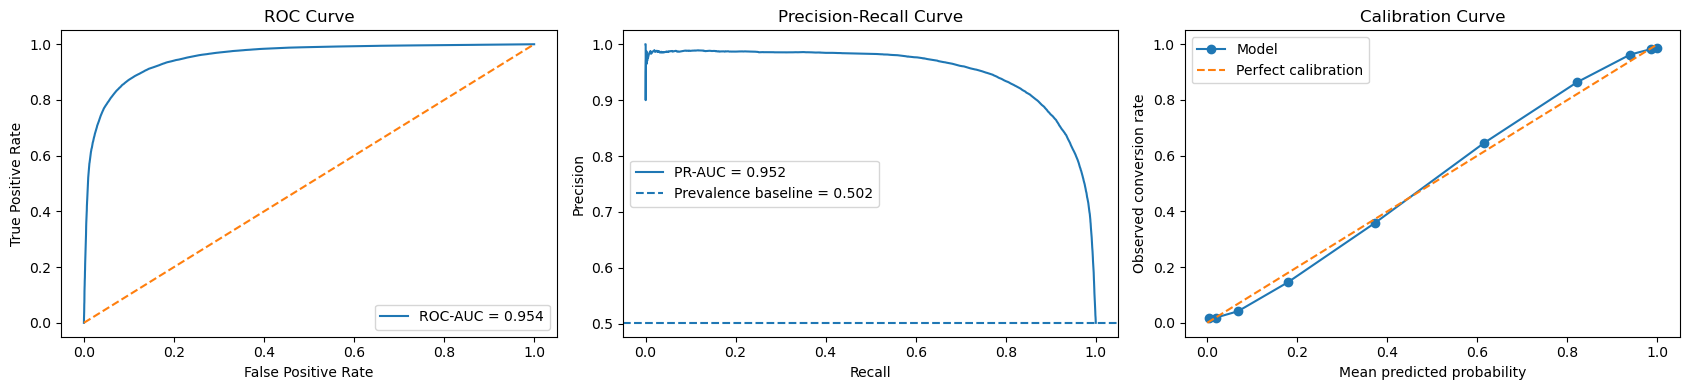

ROC-AUC: 0.9541
PR-AUC: 0.9523
PR-AUC prevalence baseline: 0.5016


In [19]:
# CELL 18 — ROC, precision-recall, and calibration curves
roc_auc = roc_auc_score(y_test, test_probabilities)
pr_auc = average_precision_score(y_test, test_probabilities)
prevalence_baseline = y_test.mean()

fpr, tpr, _ = roc_curve(y_test, test_probabilities)
precision_values, recall_values, _ = precision_recall_curve(y_test, test_probabilities)
fraction_positive, mean_predicted = calibration_curve(
    y_test, test_probabilities, n_bins=10, strategy="quantile"
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(recall_values, precision_values, label=f"PR-AUC = {pr_auc:.3f}")
axes[1].axhline(prevalence_baseline, linestyle="--",
                label=f"Prevalence baseline = {prevalence_baseline:.3f}")
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

axes[2].plot(mean_predicted, fraction_positive, marker="o", label="Model")
axes[2].plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
axes[2].set_title("Calibration Curve")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Observed conversion rate")
axes[2].legend()

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("PR-AUC prevalence baseline:", round(float(prevalence_baseline), 4))


In [24]:
# CELL 19 — Compare baseline and create test prediction output

# Majority-class baseline
majority_class = int(y_train.mode()[0])
baseline_predictions = np.full(len(y_test), majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
model_accuracy = accuracy_score(y_test, test_predictions_best)

print("Majority-class baseline accuracy:", round(baseline_accuracy, 4))
print("Logistic Regression accuracy at 0.50:", round(model_accuracy, 4))
print("ROC-AUC:", round(roc_auc, 4), "| PR-AUC:", round(pr_auc, 4))

test_output = df_model.iloc[validation_end:][
    ["lead_id", "lead_created_date"]
].copy()

test_output["actual_converted_30d"] = y_test.to_numpy()
test_output["conversion_probability"] = test_probabilities
test_output["predicted_converted_30d"] = test_predictions_best

test_output.to_csv("outputs/test_predictions.csv", index=False)

print("Saved outputs/test_predictions.csv")

test_output.head()

Majority-class baseline accuracy: 0.5016
Logistic Regression accuracy at 0.50: 0.8864
ROC-AUC: 0.9541 | PR-AUC: 0.9523
Saved outputs/test_predictions.csv


,lead_id,lead_created_date,actual_converted_30d,conversion_probability,predicted_converted_30d
425000,LD042803,2026-08-24,1,0.996795,1
425001,LD209594,2026-08-24,1,0.746476,1
425002,LD285787,2026-08-24,0,0.432934,0
425003,LD034357,2026-08-24,1,0.949506,1
425004,LD056732,2026-08-24,0,0.060621,0


In [26]:

# CELL 20 — Save metrics and model artifact, then verify loading

# Generate predictions at both thresholds
test_predictions_05 = (test_probabilities >= 0.50).astype(int)

test_predictions_capacity = (test_probabilities >= threshold).astype(int)

# Calculate test metrics
metrics = {
    "accuracy_at_0_50": float(accuracy_score(y_test, test_predictions_05)),
    "accuracy_at_capacity_threshold": float(accuracy_score(y_test, test_predictions_capacity)),
    "precision_at_capacity_threshold": float(precision_score(y_test, test_predictions_capacity, zero_division=0)),
    "recall_at_capacity_threshold": float(recall_score(y_test, test_predictions_capacity, zero_division=0)),
    "f1_at_capacity_threshold": float(f1_score(y_test, test_predictions_capacity, zero_division=0)),
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc),
    "pr_auc_prevalence_baseline": float(prevalence_baseline),
    "selected_threshold": float(threshold),
    "follow_up_capacity": float(follow_up_capacity)
}

pd.DataFrame([metrics]).to_csv("outputs/test_metrics.csv", index=False)

# Save model artifact
model_artifact = {
    "model": model,
    "numeric_imputer": numeric_imputer,
    "scaler": scaler,
    "categorical_imputer": categorical_imputer,
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "dummy_columns": dummy_columns,
    "threshold": threshold,
    "feature_columns": feature_columns
}

joblib.dump(model_artifact, "models/lead_conversion_model.joblib")

# Load saved artifact and verify predictions
loaded_artifact = joblib.load("models/lead_conversion_model.joblib")
loaded_model = loaded_artifact["model"]

loaded_probabilities = loaded_model.predict_proba(X_test_final)[:, 1]

print("Saved model and preprocessing objects.")
print("Maximum prediction difference after loading:",
      float(np.max(np.abs(test_probabilities - loaded_probabilities))))

print("Saved outputs/test_metrics.csv")
print("Notebook workflow completed — 20 code cells.")


Saved model and preprocessing objects.
Maximum prediction difference after loading: 0.0
Saved outputs/test_metrics.csv
Notebook workflow completed — 20 code cells.


In [27]:
print("Dataset shape:", df_model.shape)
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Dataset shape: (500000, 7)
Train shape: (350000, 4)
Validation shape: (75000, 4)
Test shape: (75000, 4)
